# **Лабораторна робота №4**
## **Advanced Net**
***Студент:*** Мельник Владислав

***Група:*** ФБ-61мп


# Мета роботи
***Мета:*** опанувати принципи побудови та навчання трансформерних моделей для генерації текстів або машинного перекладу; набути практичних навичок використання готових моделей Hugging Face для роботи з текстами й зображеннями.  

# Підготовка середовища та даних
Роботу виконано у Google Colab на GPU Tesla T4. Під час початкової перевірки середовища отримано Transformers 5.22.1 і Diffusers 0.42.1. У наступній комірці для встановлення вказано Transformers 4.57.1 і Diffusers 0.35.1. Після перезапуску сеансу перевірено, що у Transformers 4.57.1 доступні стислий переказ і переклад.

Архів українських речень і два текстові файли з лабораторної роботи №2 завантажено із комп’ютера. Десять PNG-зображень для порівняння завантажено окремо в пункті 3б.

In [7]:
import transformers
import diffusers
from transformers import pipeline
from diffusers import AutoPipelineForText2Image

print("Transformers:", transformers.__version__)
print("Diffusers:", diffusers.__version__)

Transformers: 5.22.1
Diffusers: 0.42.1


In [18]:
%pip -q install "transformers==4.57.1" "diffusers==0.35.1" accelerate sentencepiece sacremoses

In [3]:
from pathlib import Path
import gc, math, random, re, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from google.colab import files
from IPython.display import display
from PIL import Image, ImageOps

ROOT = Path("/content")
ROOT.mkdir(exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
assert torch.cuda.is_available(), "Виберіть GPU в меню середовища виконання."
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

def upload_to(folder):
    folder.mkdir(exist_ok=True)
    uploaded = files.upload()
    for name, data in uploaded.items():
        (folder / Path(name).name).write_bytes(data)
    print("Завантажено:", list(uploaded))

def release_memory():
    gc.collect()
    torch.cuda.empty_cache()

GPU: Tesla T4


In [12]:
upload_to(ROOT)
for name in ["ukr-eng.zip", "English_NonScam.txt", "English_Scam.txt"]:
    print(name, "✓" if (ROOT / name).is_file() else "— ще потрібно завантажити")

Saving English_NonScam.txt to English_NonScam.txt
Saving English_Scam.txt to English_Scam.txt
Saving ukr-eng.zip to ukr-eng.zip
Завантажено: ['English_NonScam.txt', 'English_Scam.txt', 'ukr-eng.zip']
ukr-eng.zip ✓
English_NonScam.txt ✓
English_Scam.txt ✓


# 1. Генерація українського тексту власним трансформером
## 1.1. Підготовка корпусу
Для навчання використано українську колонку двомовного корпусу ManyThings/Tatoeba з архіву ukr-eng.zip. Речення переведено у нижній регістр, вилучено повтори й залишено приклади довжиною від 12 до 150 символів. Після перемішування відібрано 40 000 речень: 36 000 для навчання і 4 000 для валідації. Поділ виконано до побудови словника, тому його склад визначають лише символи навчальних речень.

In [14]:
with zipfile.ZipFile(ROOT / "ukr-eng.zip") as archive:
    member = next(n for n in archive.namelist() if Path(n).name == "ukr.txt")
    lines = archive.read(member).decode("utf-8-sig").splitlines()
sentences = set()
for line in lines:
    parts = line.split("\t")
    if len(parts) >= 2:
        sentence = " ".join(parts[1].lower().split())
        if 12 <= len(sentence) <= 150:
            sentences.add(sentence)
sentences = sorted(sentences)
random.Random(SEED).shuffle(sentences)
sentences = sentences[:40000]
cut = int(0.9 * len(sentences))
train_text = "\n".join(sentences[:cut])
valid_text = "\n".join(sentences[cut:])
alphabet = ["�"] + sorted(set(train_text) - {"�"})
lookup = {ch: i for i, ch in enumerate(alphabet)}

def encode(text):
    return [lookup.get(ch, 0) for ch in text]

train_ids = torch.tensor(encode(train_text))
valid_ids = torch.tensor(encode(valid_text))
print("Навчання:", cut)
print("Валідація:", len(sentences) - cut)
print("\n".join(sentences[:5]))

Навчання: 36000
Валідація: 4000
том пообіцяв мені, що не плакатиме.
ніколи не знаєш, на що ти здатна, поки не спробуєш.
він оглянувся.
коли це закінчується?
коли ти працюватимеш?


## 1.2. Архітектура моделі
Реалізовано посимвольний трансформер типу decoder-only. Для кожної позиції модель поєднує вектор символу з вектором його позиції, а потім обробляє послідовність у трьох блоках із чотирма головами уваги в кожному. Максимальний контекст становить 96&nbsp;символів, розмір внутрішнього представлення — 128. Причинна маска закриває майбутні позиції: прогноз наступного символу залежить лише від уже доступної частини тексту. Модель має 628 177 параметрів.

In [15]:
CONTEXT, WIDTH, HEADS = 96, 128, 4

class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm1 = nn.LayerNorm(WIDTH)
        self.norm2 = nn.LayerNorm(WIDTH)
        self.qkv = nn.Linear(WIDTH, 3 * WIDTH)
        self.projection = nn.Linear(WIDTH, WIDTH)
        self.ff = nn.Sequential(nn.Linear(WIDTH, 4*WIDTH), nn.GELU(),
                                nn.Linear(4*WIDTH, WIDTH), nn.Dropout(0.1))
        self.register_buffer("mask", torch.ones(CONTEXT, CONTEXT, dtype=torch.bool).tril())

    def forward(self, x):
        batch, length, width = x.shape
        q, k, v = self.qkv(self.norm1(x)).chunk(3, dim=-1)
        def heads(t):
            return t.reshape(batch, length, HEADS, width // HEADS).transpose(1, 2)
        q, k, v = map(heads, (q, k, v))
        scores = q @ k.transpose(-2, -1) / math.sqrt(width // HEADS)
        scores = scores.masked_fill(~self.mask[:length, :length], float("-inf"))
        result = (scores.softmax(-1) @ v).transpose(1, 2).reshape(batch, length, width)
        x = x + self.projection(result)
        return x + self.ff(self.norm2(x))

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.token = nn.Embedding(len(alphabet), WIDTH)
        self.position = nn.Embedding(CONTEXT, WIDTH)
        self.blocks = nn.Sequential(*(Block() for _ in range(3)))
        self.output = nn.Sequential(nn.LayerNorm(WIDTH), nn.Linear(WIDTH, len(alphabet)))

    def forward(self, ids):
        positions = torch.arange(ids.size(1), device=ids.device)
        x = self.token(ids) + self.position(positions)
        return self.output(self.blocks(x))

gen = Generator().to(device)
print(gen)
print("Параметрів:", sum(p.numel() for p in gen.parameters()))

Generator(
  (token): Embedding(81, 128)
  (position): Embedding(96, 128)
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (qkv): Linear(in_features=128, out_features=384, bias=True)
      (projection): Linear(in_features=128, out_features=128, bias=True)
      (ff): Sequential(
        (0): Linear(in_features=128, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=128, bias=True)
        (3): Dropout(p=0.1, inplace=False)
      )
    )
    (1): Block(
      (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (qkv): Linear(in_features=128, out_features=384, bias=True)
      (projection): Linear(in_features=128, out_features=128, bias=True)
      (ff): Sequentia

## 1.3. Навчання та приклади генерації
Цільову послідовність сформовано зсувом вхідного тексту на один символ. Параметри оновлено оптимізатором AdamW, а помилку передбачення оцінено за перехресною ентропією. Для перевірки після навчання задано три початки фраз і для кожного згенеровано продовження з температурою вибірки 0,8.

1 train / val: [4.423 4.428]
250 train / val: [2.355 2.368]
500 train / val: [2.121 2.141]
750 train / val: [1.896 1.932]
1000 train / val: [1.771 1.778]
1250 train / val: [1.657 1.661]
1500 train / val: [1.578 1.581]


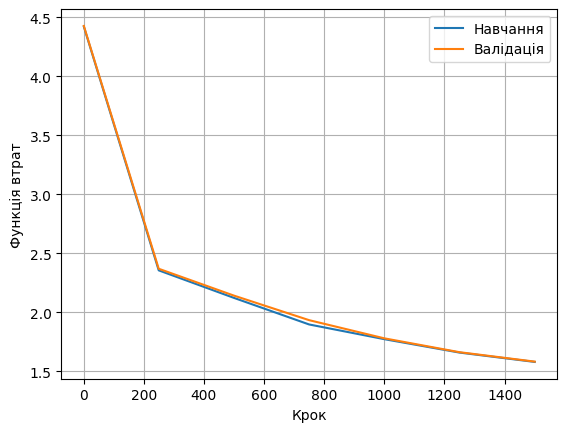

Початок: сьогодні вранці
Результат: сьогодні вранці.
цей вам залишити пізні.
де я не вже зробити на ноча гаду.
це не надвається вашомусти з кратися вичізналистовну.
том сьогодну певер.
том пр
Початок: мій друг
Результат: мій друга.
я все виграти з вамку.
том плишає витра сепробати мені.
я знаю, що тут тому.
і почав.
думаю, як тому пробила це зробити.
я пізномого це с
Початок: коли я повернувся
Результат: коли я повернувся не вкаже розі.
собак до полює хвортів.
ви чити на інше.
я хочу бути шаспетці.
гроше французькою значила тома.
ви була всід?
том це щодятне 


In [16]:
def batch_loss(data):
    starts = torch.randint(len(data) - CONTEXT, (32, 1))
    indices = starts + torch.arange(CONTEXT)
    logits = gen(data[indices].to(device))
    targets = data[indices + 1].to(device)
    return F.cross_entropy(logits.flatten(0, 1), targets.flatten())

optim = torch.optim.AdamW(gen.parameters(), lr=5e-4)
history = []
for step in range(1, 1501):
    gen.train()
    optim.zero_grad()
    loss = batch_loss(train_ids)
    loss.backward()
    nn.utils.clip_grad_norm_(gen.parameters(), 1.0)
    optim.step()
    if step == 1 or step % 250 == 0:
        gen.eval()
        with torch.no_grad():
            means = [np.mean([batch_loss(data).item() for _ in range(10)])
                     for data in (train_ids, valid_ids)]
        history.append([step, *means])
        print(step, "train / val:", np.round(means, 3))
pd.DataFrame(history, columns=["Крок", "Навчання", "Валідація"]).plot(x="Крок", grid=True)
plt.ylabel("Функція втрат")
plt.show()

gen.eval()
with torch.inference_mode():
    for prompt in ["сьогодні вранці", "мій друг", "коли я повернувся"]:
        ids = torch.tensor([encode(prompt)], device=device)
        for _ in range(140):
            logits = gen(ids[:, -CONTEXT:])[:, -1, :] / 0.8
            logits[:, 0] = float("-inf")
            ids = torch.cat([ids, torch.multinomial(logits.softmax(-1), 1)], dim=1)
        print("Початок:", prompt)
        print("Результат:", "".join(alphabet[i] for i in ids[0].tolist()))
gen.cpu()
del optim
release_memory()

За 1 500 кроків навчальна втрата зменшилася з 4,423 до 1,578, а валідаційна — з 4,428 до 1,581. На графіку обидві криві знижуються близько одна до одної. Модель стала краще передбачати наступний символ і на відкладених прикладах. Водночас якість цілих речень обмежена. Наприклад, у продовженні «я хочу бути шаспетці» початок граматично впізнаваний, але останнє слово вигадане. В інших прикладах трапляються справжні слова, зв’язок між якими важко пояснити.

# 2а. Експерименти з текстовими моделями Hugging Face
Через інтерфейс pipeline перевірено три моделі на різних українських текстах. Для класифікації без прикладів навчання використано XLM-RoBERTa-XNLI і задано три можливі теми. Для стислого переказу подано моделі mT5 XLSum абзац про дослідження електроспоживання в школі. Для перекладу з української англійською використано OPUS-MT.

In [3]:
from transformers import pipeline

text = "Дослідники навчили нейронну мережу розрізняти види дерев за фотографіями листя."
pipe = pipeline("zero-shot-classification", model="joeddav/xlm-roberta-large-xnli", device=0)
r = pipe(text, candidate_labels=["технології", "музика", "спорт"],
         hypothesis_template="Тема цього тексту — {}.")
print(text)
display(pd.DataFrame({"Тема": r["labels"], "Оцінка": r["scores"]}))
del pipe
release_memory()

article = ("Учні протягом тижня вимірювали споживання електроенергії у школі. "
           "Щодня вони записували показники лічильника до та після уроків. "
           "Найбільші витрати зафіксували в кабінетах, де ввечері залишали освітлення. "
           "Учні запропонували перевіряти світло наприкінці дня і повторити вимірювання через місяць.")
pipe = pipeline("summarization", model="csebuetnlp/mT5_multilingual_XLSum", device=0)
print(article)
print("Переказ:", pipe(article, min_new_tokens=5, max_new_tokens=45)[0]["summary_text"])
del pipe
release_memory()

sentence = "Студенти перевірили обидві моделі на тих самих тестових даних."
pipe = pipeline("translation", model="Helsinki-NLP/opus-mt-uk-en", device=0)
print(sentence)
print("Переклад:", pipe(sentence)[0]["translation_text"])
del pipe
release_memory()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Some weights of the model checkpoint at joeddav/xlm-roberta-large-xnli were not used when initializing XLMRobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing XLMRobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if y

Дослідники навчили нейронну мережу розрізняти види дерев за фотографіями листя.


,Тема,Оцінка
0,спорт,0.527648
1,технології,0.364679
2,музика,0.107672


pytorch_model.bin:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.33G [00:00<?, ?B/s]

... (10 outputs left out)

target.spm:   0%|          | 0.00/809k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0


Студенти перевірили обидві моделі на тих самих тестових даних.
Переклад: The students checked both models for the same test data.


***Аналіз результатів.*** Для речення про розпізнавання дерев нейронною мережею очікувалася тема «технології». Модель поставила її другою (0,365), а найвищу оцінку надала темі «спорт» (0,528). У переказі модель зберегла згадку про електроенергію, проте змінила саму подію: замість вимірювань у школі повідомила про відключення електроенергії у восьми тисяч школярів у Китаї. Таких відомостей у початковому тексті немає. Переклад передав головну думку про порівняння моделей на однакових даних. Вислів «on the same test data» точніше передає українське «на тих самих тестових даних», ніж отримане «for the same test data».

# 2б. Донавчання класифікатора та порівняння з ЛР №2
## 2.1. Відтворення базової моделі
Для порівняння використано ті самі англомовні розмови й той самий порядок підготовки даних, що й у ЛР №2. Клас 0 відповідає звичайній розмові (Non-scam), клас 1 — шахрайській (Scam). Після очищення та вилучення повторів залишилося 793 тексти. Стратифікований поділ із фіксованим random_state=42 дав 634 навчальні та 159 тестових прикладів. На цьому поділі спочатку відтворено TF-IDF із класифікатором Multinomial Naive Bayes та звірено його матрицю помилок із попередньою роботою.

Разом, навчання, тест: 793, 634, 159
Accuracy ЛР №2: 96.86%


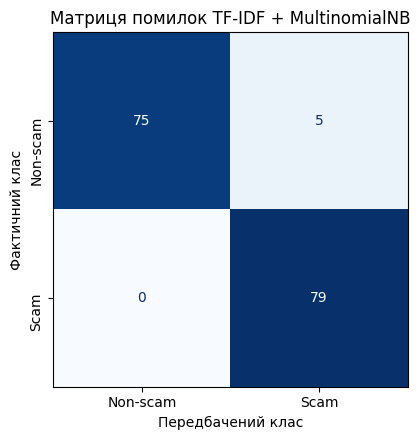

In [9]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
)

rows = []
for label, filename in enumerate(["English_NonScam.txt", "English_Scam.txt"]):
    raw = (ROOT / filename).read_text(encoding="utf-8-sig")
    lines = [s.strip() for s in raw.splitlines() if s.strip()]
    assert len(lines) == 400, f"Перевірте {filename}"
    rows.extend((s, label) for s in lines)

calls = pd.DataFrame(rows, columns=["text", "label"])

def clean(text):
    text = re.sub(r"\[[^\]]*\]", " ", text.lower())
    return " ".join(re.sub(r"[^a-z\s]", " ", text).split())

calls["clean"] = calls.text.map(clean)
calls = calls[calls.clean.str.len() > 0].copy()
counts = calls.groupby("clean").label.nunique()
calls = calls[~calls.clean.isin(counts[counts > 1].index)]
calls = calls.drop_duplicates("clean").reset_index(drop=True)

Xtr, Xte, ytr, yte = train_test_split(
    calls.clean, calls.label, test_size=0.2,
    random_state=42, stratify=calls.label
)

print(f"Разом, навчання, тест: {len(calls)}, {len(Xtr)}, {len(Xte)}")
assert (len(calls), len(Xtr), len(Xte)) == (793, 634, 159)

stop = set(ENGLISH_STOP_WORDS) - {"no", "not", "never", "nor"}
vec = TfidfVectorizer(ngram_range=(1, 2), stop_words=sorted(stop))
nb = MultinomialNB().fit(vec.fit_transform(Xtr), ytr)
old = nb.predict(vec.transform(Xte))

print(f"Accuracy ЛР №2: {accuracy_score(yte, old):.2%}")

# Обчислюємо матрицю та перевіряємо збіг із результатом ЛР №2
cm = confusion_matrix(yte, old, labels=[0, 1])
assert cm.tolist() == [[75, 5], [0, 79]], "Перевірте початкові файли та порядок рядків."

# Виводимо матрицю як рисунок
fig, ax = plt.subplots(figsize=(6, 4.5))
matrix_plot = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-scam", "Scam"]
)
matrix_plot.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Матриця помилок TF-IDF + MultinomialNB")
ax.set_xlabel("Передбачений клас")
ax.set_ylabel("Фактичний клас")
ax.tick_params(axis="y", labelrotation=90)
fig.tight_layout()
plt.show()

## 2.2. Повне донавчання DistilBERT
Для англомовних розмов обрано distilbert-base-uncased. На вхід подавалися очищені тексти, які токенізовано токенізатором моделі. Протягом двох епох оновлювалися параметри всього трансформера та класифікаційного шару. Розмір навчального пакета становив 8 текстів, швидкість навчання — 0,00002.

In [10]:
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

torch.manual_seed(SEED)
name = "distilbert/distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)
model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2).to(device)

def collate(rows):
    texts, labels = zip(*rows)
    batch = tok(list(texts), padding=True, truncation=True, max_length=256, return_tensors="pt")
    batch["labels"] = torch.tensor(labels)
    return {k: v.to(device) for k, v in batch.items()}

train_loader = DataLoader(list(zip(Xtr, ytr)), batch_size=8, shuffle=True, collate_fn=collate)
test_loader = DataLoader(list(zip(Xte, yte)), batch_size=16, shuffle=False, collate_fn=collate)
opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
for epoch in range(1, 3):
    model.train()
    total = 0.
    for batch in tqdm(train_loader, desc=f"Епоха {epoch}/2"):
        opt.zero_grad()
        loss = model(**batch).loss
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.)
        opt.step()
        total += loss.item() * len(batch["labels"])
    print("Середня втрата:", round(total / len(Xtr), 4))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Епоха 1/2:   0%|          | 0/80 [00:00<?, ?it/s]

Середня втрата: 0.2943


Епоха 2/2:   0%|          | 0/80 [00:00<?, ?it/s]

Середня втрата: 0.0159


## 2.3. Результати на спільній тестовій вибірці
Середня навчальна втрата зменшилася з 0,2943 до 0,0159. Щоб оцінити, як це позначилося на класифікації нових розмов, для обох моделей обчислено Accuracy, Precision, Recall і F1 на тих самих 159 тестових прикладах. Окремо порівнювалися хибні тривоги та пропущені шахрайські розмови.

In [11]:
new = []
model.eval()
with torch.inference_mode():
    for batch in test_loader:
        batch.pop("labels")
        new.extend(model(**batch).logits.argmax(1).cpu().tolist())
results = []
for label, pred in [("TF-IDF + MultinomialNB", old), ("DistilBERT", new)]:
    report = classification_report(yte, pred, target_names=["Non-scam", "Scam"],
                                   output_dict=True, zero_division=0)
    cm = confusion_matrix(yte, pred, labels=[0, 1])
    print(label)
    display(pd.DataFrame(report).T.round(4))
    results.append([label, len(yte), accuracy_score(yte, pred), report["macro avg"]["f1-score"],
                    report["Scam"]["recall"], cm[0, 1], cm[1, 0]])
comparison = pd.DataFrame(results, columns=["Модель", "Тест", "Accuracy", "Macro F1",
                                           "Recall Scam", "Хибні тривоги", "Пропущені Scam"])
display(comparison.round(4))
comparison.to_csv(ROOT / "comparison.csv", index=False)
del opt, model
release_memory()

TF-IDF + MultinomialNB


,precision,recall,f1-score,support
Non-scam,1.0000,0.9375,0.9677,80.0000
Scam,0.9405,1.0000,0.9693,79.0000
accuracy,0.9686,0.9686,0.9686,0.9686
macro avg,0.9702,0.9688,0.9685,159.0000
weighted avg,0.9704,0.9686,0.9685,159.0000


DistilBERT


,precision,recall,f1-score,support
Non-scam,0.9518,0.9875,0.9693,80.0000
Scam,0.9868,0.9494,0.9677,79.0000
accuracy,0.9686,0.9686,0.9686,0.9686
macro avg,0.9693,0.9684,0.9685,159.0000
weighted avg,0.9692,0.9686,0.9685,159.0000


,Модель,Тест,Accuracy,Macro F1,Recall Scam,Хибні тривоги,Пропущені Scam
0,TF-IDF + MultinomialNB,159,0.9686,0.9685,1.0000,5,0
1,DistilBERT,159,0.9686,0.9685,0.9494,1,4


Обидві моделі правильно класифікували 154 зі 159 розмов. Вони отримали однакові Accuracy (96,86 %) та Macro F1 (0,9685), але припустилися різних помилок. Базова модель виявила всі 79 шахрайських розмов і помилково віднесла до цього класу 5 звичайних. DistilBERT зменшив кількість хибних тривог до однієї, однак пропустив 4 шахрайські розмови. Для класу Scam його Precision зріс із 0,9405 до 0,9868, а Recall знизився з 1,0000 до 0,9494. Отже, на цій вибірці попередження DistilBERT рідше було хибним, тоді як базова модель виявила більше випадків шахрайства.

# 3а. Генерація зображення за текстовим описом
Для експерименту Text-to-Image використано SD-Turbo з бібліотеки Diffusers. В описі задано невелику метеостанцію на трав’янистому пагорбі, чашковий анемометр й опадомір на передньому плані та м’яке ранкове світло. Повний англомовний запит і згенероване зображення наведено під коміркою.

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

merges.txt: 0.00B [00:00, ?B/s]

scheduler_config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (8 outputs left out)

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


  0%|          | 0/1 [00:00<?, ?it/s]

Запит: A realistic photograph of a small weather station on a grassy hill in northern Ukraine, a cup anemometer and a rain gauge in the foreground, soft morning light


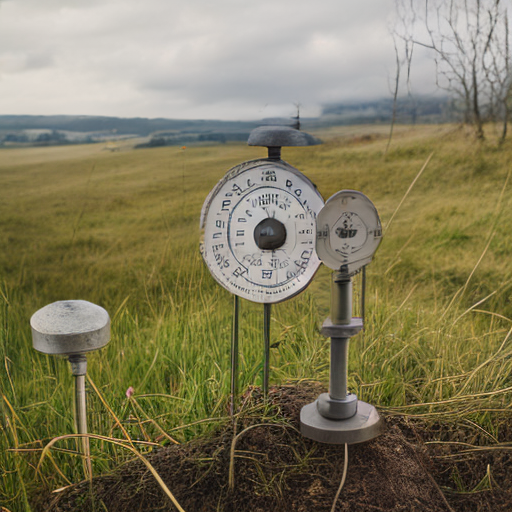

In [12]:
from diffusers import AutoPipelineForText2Image
prompt = ("A realistic photograph of a small weather station on a grassy hill in northern Ukraine, "
          "a cup anemometer and a rain gauge in the foreground, soft morning light")
pipe = AutoPipelineForText2Image.from_pretrained(
    "stabilityai/sd-turbo", torch_dtype=torch.float16, variant="fp16").to(device)
image = pipe(prompt=prompt, num_inference_steps=1, guidance_scale=0.,
             generator=torch.Generator(device=device).manual_seed(SEED)).images[0]
print("Запит:", prompt)
display(image)
image.save(ROOT / "generated_image.png")
del pipe
release_memory()

Модель відтворила трав’янистий схил і винесла вимірювальні прилади на передній план. Освітлення м’яке, як передбачено в описі. Загальна сцена відповідає запиту, хоча за формою зображених приладів складно впевнено розпізнати саме чашковий анемометр та опадомір.

# 3б. Порівняння зображень за векторами ознак DINOv2
Обрано десять зображень у відтінках сірого. Вони відрізняються зернистістю, шириною горизонтальних смуг і розміром однорідних ділянок. Після впорядкування файлів за назвами кожному зображенню присвоєно номер від 1 до 10. Ця нумерація однакова на ілюстраціях і в матриці відстаней.

Saving 029fa402177fab8729a6b1733633ac50.png to 029fa402177fab8729a6b1733633ac50.png
Saving 0030e458f08bb8966a17d084e6f38b1f.png to 0030e458f08bb8966a17d084e6f38b1f.png
Saving 0060f7b9a21b3d0b777ce774db1a16b5.png to 0060f7b9a21b3d0b777ce774db1a16b5.png
Saving 085432ce42cc46f50cea9fdfb9a084f6.png to 085432ce42cc46f50cea9fdfb9a084f6.png
Saving 0318483f282dd2bcd377e17980c86557.png to 0318483f282dd2bcd377e17980c86557.png
Saving 002120188c84951a2c18606ba982aa9a.png to 002120188c84951a2c18606ba982aa9a.png
Saving 064749705a355f0ce7ba5008523aeda9.png to 064749705a355f0ce7ba5008523aeda9.png
Saving 0860399916ef026825ecc631f305d96e.png to 0860399916ef026825ecc631f305d96e.png
Saving 007442180213429be7267099a344704b.png to 007442180213429be7267099a344704b.png
Saving 044707062722999755812466351afbe2.png to 044707062722999755812466351afbe2.png
1 002120188c84951a2c18606ba982aa9a.png
2 0030e458f08bb8966a17d084e6f38b1f.png
3 0060f7b9a21b3d0b777ce774db1a16b5.png
4 007442180213429be7267099a344704b.png
5 02

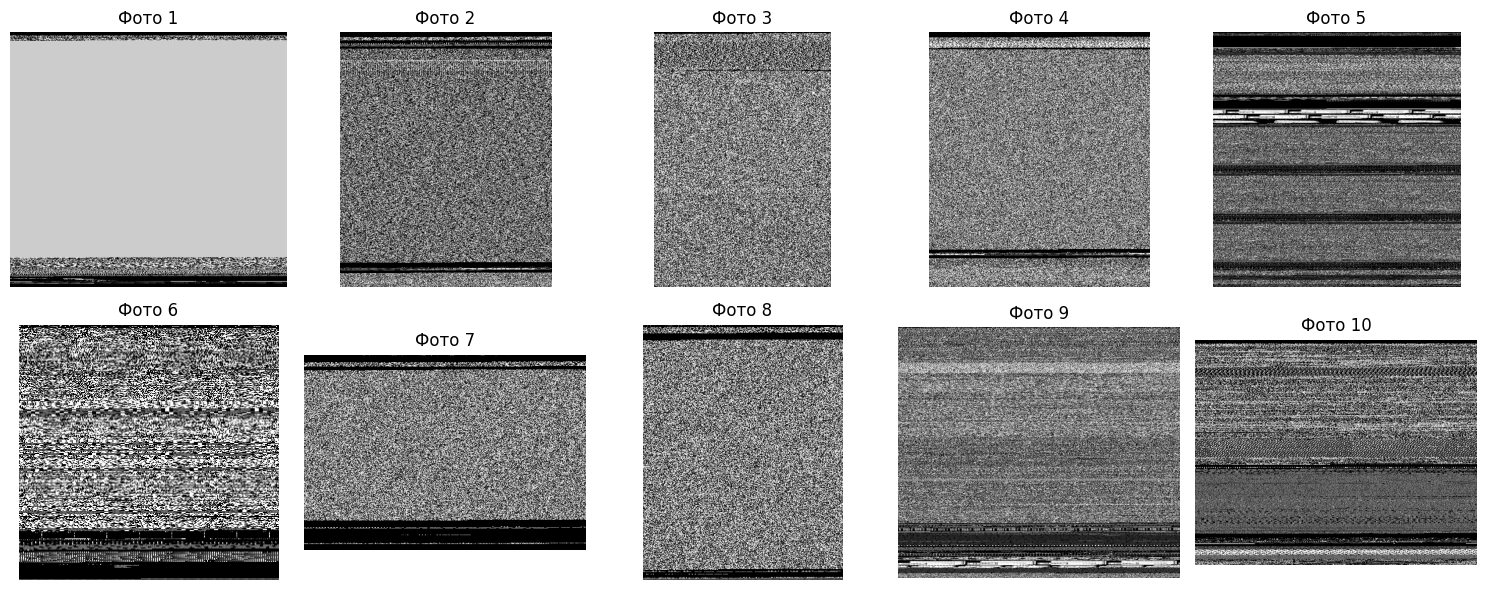

In [4]:
import io
uploaded = files.upload()
names_img = sorted(n for n in uploaded if Path(n).suffix.lower() in {".jpg", ".jpeg", ".png"})
assert len(names_img) == 10, "Виберіть одночасно 10 JPG/PNG."
images = []
for name in names_img:
    with Image.open(io.BytesIO(uploaded[name])) as img:
        images.append(ImageOps.exif_transpose(img).convert("RGB"))
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, (ax, img, name) in enumerate(zip(axes.flat, images, names_img), 1):
    print(i, name)
    ax.imshow(img)
    ax.set_title(f"Фото {i}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## ***Виділення ознак та обчислення відстаней***
Для кожного зображення взято 384-вимірний вектор першого токена (CLS) з останнього прихованого шару DINOv2. Кожен вектор $v_i$ поділено на його евклідову норму, а потім для кожної пари обчислено відстань між нормованими векторами:
$$
\hat{v}_i = \frac{v_i}{\lVert v_i \rVert_2}, \qquad d_{ij} = \lVert \hat{v}_i - \hat{v}_j \rVert_2.
$$

Тут $v_i$ — вектор ознак зображення $i$, $\hat{v}_i$ — його нормований вектор, а $d_{ij}$ — відстань між нормованими векторами зображень $i$ та $j$.

Отримана матриця має розмір $10\times10$. Для пошуку крайніх значень використано її верхню трикутну частину без діагоналі. Так кожна з 45 пар різних зображень враховується один раз.

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Розмірність: (10, 384)
Норми: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]



,Фото 1,Фото 2,Фото 3,Фото 4,Фото 5,Фото 6,Фото 7,Фото 8,Фото 9,Фото 10
Фото 1,0.000,0.764,0.896,0.837,1.082,0.919,0.814,0.912,0.913,0.957
Фото 2,0.764,0.000,0.854,0.639,1.032,1.022,0.599,0.874,0.902,0.984
Фото 3,0.896,0.854,0.000,0.969,1.188,1.003,0.899,0.185,1.102,1.134
Фото 4,0.837,0.639,0.969,0.000,0.843,0.962,0.510,1.010,0.829,0.905
Фото 5,1.082,1.032,1.188,0.843,0.000,0.905,0.926,1.217,0.759,0.697
Фото 6,0.919,1.022,1.003,0.962,0.905,0.000,0.919,1.012,0.645,0.720
Фото 7,0.814,0.599,0.899,0.510,0.926,0.919,0.000,0.946,0.838,0.932
Фото 8,0.912,0.874,0.185,1.010,1.217,1.012,0.946,0.000,1.123,1.149
Фото 9,0.913,0.902,1.102,0.829,0.759,0.645,0.838,1.123,0.000,0.594
Фото 10,0.957,0.984,1.134,0.905,0.697,0.720,0.932,1.149,0.594,0.000


Унікальних пар: 45



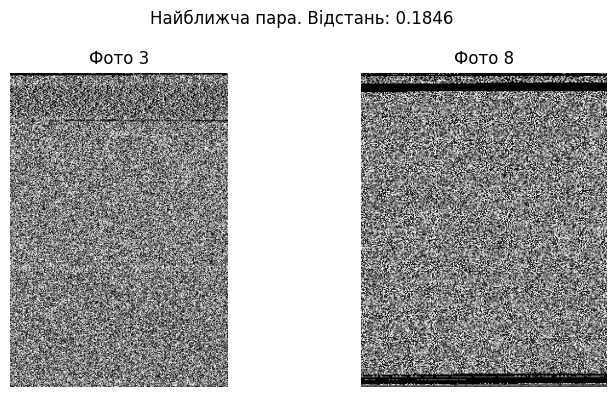

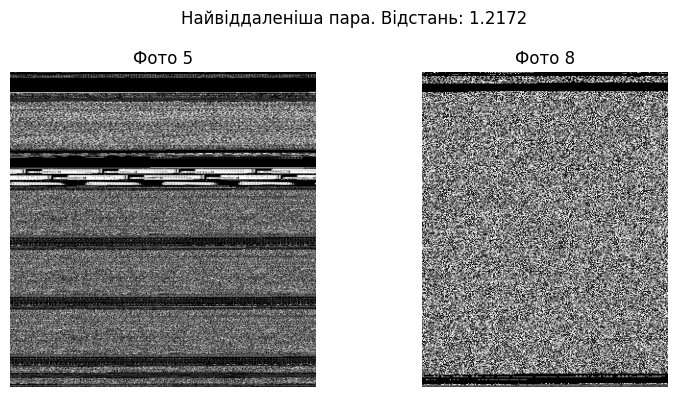

In [9]:
from transformers import AutoModel, AutoImageProcessor
processor = AutoImageProcessor.from_pretrained("facebook/dinov2-small")
dino = AutoModel.from_pretrained("facebook/dinov2-small").to(device).eval()
inputs = processor(images=images, return_tensors="pt").to(device)
with torch.inference_mode():
    features = dino(**inputs).last_hidden_state[:, 0, :]
    normalized = F.normalize(features, p=2, dim=1)
    distances = torch.cdist(normalized, normalized, p=2).cpu().numpy()
print("Розмірність:", tuple(features.shape))
print("Норми:", normalized.norm(dim=1).cpu().numpy().round(4))
print()
labels = [f"Фото {i}" for i in range(1, 11)]
table = pd.DataFrame(distances, index=labels, columns=labels)
display(table.round(3))
table.to_csv(ROOT / "distances.csv")
r, c = np.triu_indices(10, k=1)
values = distances[r, c]
print("Унікальних пар:", len(values))
print()
for title, pos in [("Найближча", values.argmin()), ("Найвіддаленіша", values.argmax())]:
    i, j = r[pos], c[pos]
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    for ax, k in zip(axes, [i, j]):
        ax.imshow(images[k])
        ax.set_title(labels[k])
        ax.axis("off")
    fig.suptitle(f"{title} пара. Відстань: {values[pos]:.4f}")
    plt.tight_layout()
    plt.show()

***Візуальна інтерпретація.*** Найближчими виявилися зображення 3 і 8 (відстань 0,1846). В обох майже все поле заповнене дрібнозернистою сірою текстурою, хоча у зображення 8 помітні темні смуги по краях. Найбільша відстань — 1,2172 — між зображеннями 5 і 8. На зображенні 5 через усе поле проходять контрастні горизонтальні смуги різної ширини, тоді як центральна частина зображення 8 має рівномірну зернистість. Для обох пар результат узгоджується з моєю візуальною оцінкою.

# Загальні висновки
У ході лабораторної роботи відстежено різницю між якістю передбачення окремого символу та змістовністю згенерованого тексту. Навіть після зниження валідаційної втрати до 1,581 власний трансформер утворював помилкові слова. Експеримент із переказом показав іншу проблему: граматично зрозуміле речення може містити факти, яких не було в оригіналі.

Під час класифікації розмов найважливішим для порівняння виявився тип помилки. За однакової точності 96,86 % донавчений DistilBERT дав менше хибних тривог, але пропустив чотири шахрайські розмови. У завданнях із зображеннями SD-Turbo краще відтворила загальний вигляд сцени, ніж форму окремих приладів, а для DINOv2 найбільша й найменша відстані відповідали помітним відмінностям і подібності текстур.